# Reverse liquidity stress and the liquidity validation tests

**Question:** How much faster than the LiST Adverse and Extreme tables must the deposits of the bank that failed in 2023 leave for it to survive only 30 days, and when does the engine refuse to give a number?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 04 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the reverse liquidity stress as a question ("how much faster must the deposits leave for the bank to survive only 30 days?") and answer it with the engine as a multiplier of the run-off rates;
- explain the cap on the multiplier (no rate above 1), the threshold property of the solution and the three reasons the engine refuses a target;
- read the validation tests of the liquidity package: the round trip of the solver, the monotonicity of the survival period and the NLP identity;
- read the cost of a shorter survival as a curve of multipliers, and the cliff of the position as a diagnostic.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Three committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/reverse-stress.json`: the reverse stress of three bases (LiST Adverse, LiST Extreme and the fast run) at a target of 30 days: the cap, the curve of the survival period against the multiplier, the solved multiplier with its round trip, and the test rows.
- `data/derived/C16/list-adverse.json` and `data/derived/C16/list-extreme.json`: the ladders (segments, daily series) from which the scenarios of the two LiST bases are rebuilt, as in notebook 04.

The question comes from the liquidity model ladder of the research (reverse liquidity stress, rung 5 of the ladder: the run-off multiplier at which the survival period falls below a target, for example 30 days), and from the supervisory practice of stressing in many scenarios, short and protracted, individually and in combination (BCBS, 2008, Principle 10). Amounts are in USD thousands.

In [2]:
# Load the three committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "list-adverse", "list-extreme"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)

reverse_doc = documents["reverse-stress"]
outputs = reverse_doc["outputs"]
bases = {base["base_id"]: base for base in outputs["bases"]}
print("target of the document (days):", outputs["target"]["days"])

reverse-stress | baked by riskvalidation 1.0.1 | installed 1.0.1
list-adverse | baked by riskvalidation 1.0.1 | installed 1.0.1
list-extreme | baked by riskvalidation 1.0.1 | installed 1.0.1
target of the document (days): 30


## Method

### Step 1: the scenario and a CBC that the engine can use

The reverse stress takes a base scenario (segments with a class and an opening balance, notebook 04) and a daily CBC. The engine's solver computes the NLP from the CBC and the behavioural outflows of the segments, and it takes no inflows and no contractual outflows. The ladder of the document does have them, so the document hands the solver an **effective CBC** that absorbs both and leaves the NLP of the ladder untouched:

$$\mathrm{CBC}^{\mathrm{eff}}(t) = \mathrm{CBC}(t) + \sum_{s \le t} I(s) - \sum_{s \le t} O_{\text{contractual}}(s), \qquad \mathrm{NLP}(t) = \mathrm{CBC}^{\mathrm{eff}}(t) - \sum_{s \le t} O_{\text{segments}}(s)$$

This is a convention of the product's document (the engine does not impose it), and the identity is checkable: the next cell composes the Adverse and Extreme scenarios from the committed segments, builds the effective CBC, and runs the test `liq.nlp_identity`, whose statistic is the largest absolute residual between the engine's NLP from the effective CBC and the committed NLP of the ladder.

In [3]:
# Compose the two LiST bases, build the effective CBC and test the identity of the NLP
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario
from riskvalidation.validation.liquidity import nlp_identity

conventions = outputs["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    args = (row["scenario_family"], row["phase"], list_scenario(severity))
    scenario = compose_scenario(*args, segments, row["horizon_days"])
    segment_outflows = scenario.outflows().sum(axis=0)
    contractual = np.array(lad["total_outflows"]) - segment_outflows
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    no_inflows = np.zeros_like(segment_outflows)
    identity = nlp_identity(effective_cbc, segment_outflows, no_inflows, np.array(lad["nlp"]))
    built[base_id] = (scenario, effective_cbc)
    print(base_id, "| identity test, largest residual:", round(identity.statistic, 9), identity.light.value)

list-adverse | identity test, largest residual: 7e-09 green
list-extreme | identity test, largest residual: 3e-08 green


### Step 2: the multiplier, its cap and the curve of the survival period

A multiplier $m \ge 1$ scales every segment's daily rate, with the rate kept at most 1 (a rate cannot be more than all of the stock):

$$q_s'(d) = \min\bigl(m\, q_s(d),\; 1\bigr), \qquad m_{\max} = \frac{1}{\max\{\, q_s(d) : q_s(d) < 1 \,\}}$$

The cap $m_{\max}$ is the multiplier at which the largest rate below 1 reaches 1; beyond it, scaling no longer changes the segment that matters, so a point beyond the cap is refused. A rate already at 1 (the financial segment) stays at 1. The survival period $\mathrm{SP}(m)$ is non-increasing in $m$, and "survives the horizon" counts as longer than any day. `max_multiplier` gives the cap and `survival_vs_multiplier` gives the survival period under each multiplier of a grid; the grid of the document is a stated convention (1, 1.25, 1.5, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144). The next cell computes both bases and prints the curves.

In [4]:
# The cap and the survival period under each multiplier of the grid, for the two LiST bases
from riskvalidation.liquidity.reverse import max_multiplier, survival_vs_multiplier

grid_all = conventions["runoff_multiplier_grid"]["values"]
curves = {}
for base_id, (scenario, effective_cbc) in built.items():
    cap = max_multiplier(scenario)
    grid = np.array([m for m in grid_all if m <= cap])
    results = survival_vs_multiplier(scenario, effective_cbc, grid)
    days = [None if r.survives else r.day for r in results]
    curves[base_id] = (grid, days)
    print(base_id, "| cap:", round(cap, 6))
    print("   multipliers:", [float(m) for m in grid])
    print("   survival days:", days)
    print("   non-increasing:", all(a >= b for a, b in zip(days, days[1:])))

list-adverse | cap: 145.234634
   multipliers: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0, 144.0]
   survival days: [62, 50, 42, 32, 22, 13, 9, 5, 1, 1, 1, 1, 1]
   non-increasing: True
list-extreme | cap: 93.876528
   multipliers: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0]
   survival days: [41, 34, 28, 21, 15, 9, 6, 4, 1, 1, 1, 1]
   non-increasing: True


### Step 3: solving for the threshold multiplier

The survival period reaches a target of $T$ days when the NLP is negative on some day up to $T$: $\mathrm{SP}(m) \le T \iff \min_{t \le T} \mathrm{NLP}(t; m) < 0$. That minimum is a continuous, non-increasing function of $m$, so the root is bracketed between $m = 1$ and the cap and found with Brent's method (`scipy.optimize.brentq`). The survival period is an integer day, so the answer is the **threshold multiplier** $m^*$: the smallest $m$, rounded up to six decimals and never above the cap, at which $\mathrm{SP}(m) \le T$.

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

The second inequality is the round trip: the solution reaches the target, and a hair below it the target is not yet reached. `solve_multiplier` returns the multiplier, the survival period at it and the survival period just below it. The test `liq.reverse_stress_round_trip` checks exactly that property. The next cell solves for the target of the document (30 days) on both bases and runs the test.

In [5]:
# Solve for the threshold multiplier at the target of the document and test the round trip
from riskvalidation.liquidity.reverse import solve_multiplier
from riskvalidation.validation.liquidity import reverse_stress_round_trip

target = outputs["target"]["days"]
solutions = {}
for base_id, (scenario, effective_cbc) in built.items():
    solution = solve_multiplier(scenario, effective_cbc, target)
    solutions[base_id] = solution
    below = solution.survival_just_below
    test = reverse_stress_round_trip(
        solution.multiplier, solution.survival_at_multiplier, target, 0.0, survival_just_below=below
    )
    print(base_id, "| status:", solution.status, "| m* =", solution.multiplier)
    print("   survival at m*:", solution.survival_at_multiplier, "| just below m* (6 decimals):", below.day)
    print("   round trip test:", test.statistic, test.light.value)

list-adverse | status: solved | m* = 2.118175
   survival at m*: 30 | just below m* (6 decimals): 31
   round trip test: 0.0 green
list-extreme | status: solved | m* = 1.383141
   survival at m*: 30 | just below m* (6 decimals): 31
   round trip test: 0.0 green


The next cell draws the survival period against the multiplier for both bases, with the target of 30 days as a horizontal line and the threshold multipliers as vertical marks.

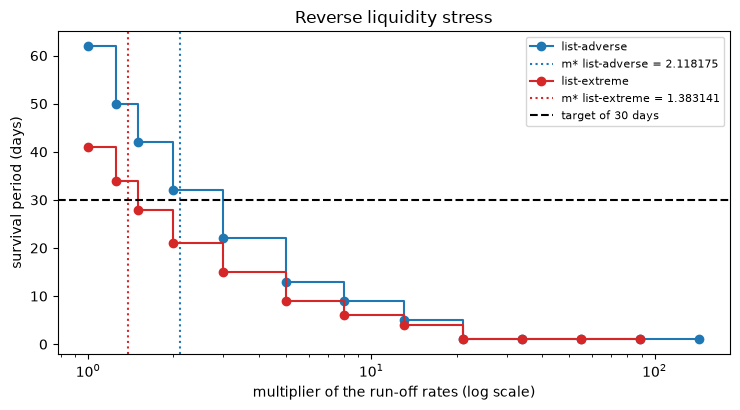

In [6]:
# Draw the survival period against the multiplier of the run-off rates, with the target and the thresholds
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (base_id, (grid, days)), color in zip(curves.items(), ("tab:blue", "tab:red")):
    ax.step(grid, days, where="post", marker="o", color=color, label=base_id)
    m_star = solutions[base_id].multiplier
    ax.axvline(m_star, color=color, linestyle=":", label=f"m* {base_id} = {m_star}")
ax.axhline(target, color="black", linestyle="--", label="target of 30 days")
ax.set_xscale("log")
ax.set_xlabel("multiplier of the run-off rates (log scale)")
ax.set_ylabel("survival period (days)")
ax.set_title("Reverse liquidity stress")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both step curves fall steeply and then flatten at day 1. Under Adverse the bank lasts 62 days at the tables, 32 days at a multiplier of 2 and 1 day from 21 on; under Extreme it starts at 41 and also reaches 1 day from 21. The dotted verticals are the answer to the question: the curve meets the 30-day line at 2.118175 for Adverse and 1.383141 for Extreme, so the target is a small multiple of the tables. The log axis stretches the small multipliers, where all the action is, and the figure does not say whether such speeds are plausible, which is the question of the next notebook.

### Step 4: when the engine refuses

A target that is not bracketed is refused with its reason, never answered with a number. There are three reasons: the target is not below the horizon (a survival period under it cannot be told from surviving the horizon); the base survival period is already at or below the target (there is nothing to reverse); or no multiplier under the cap reaches the target. In this case only the first two arise: every base reaches day 1 under its cap (the curves of step 2 end at 1). The fast-run base of the document is refused for the first reason: its horizon is 5 days and the target is 30. The next cell asks the engine for six targets on the Adverse base (an exploration, not committed rows) and classifies each answer, then prints the committed refusal of the fast run in the language of the notebook.

In [7]:
# Six targets on the Adverse base: the engine answers with a multiplier or refuses with one of the three reasons
scenario, effective_cbc = built["list-adverse"]
reasons = (
    ("not below the horizon", "not below the horizon"),
    ("already at or below", "base survival already at or below the target"),
)
fallback = "no multiplier under the cap reaches it"
for days_target in (5, 31, 62, 124, 125, 200):
    answer = solve_multiplier(scenario, effective_cbc, days_target)
    if answer.status == "solved":
        print(f"target {days_target:4d} | solved | m* = {answer.multiplier}")
    else:
        why = next((label for key, label in reasons if key in answer.reason), fallback)
        print(f"target {days_target:4d} | refused: {why} | m* = {answer.multiplier}")

fast_run = bases["fast-run"]
print("fast run, as baked:", fast_run["solved"]["status"])
print(fast_run["solved"]["refusal_reason"]["en"])

target    5 | solved | m* = 12.65873
target   31 | solved | m* = 2.047593
target   62 | refused: base survival already at or below the target | m* = None
target  124 | refused: base survival already at or below the target | m* = None
target  125 | refused: not below the horizon | m* = None
target  200 | refused: not below the horizon | m* = None
fast run, as baked: refused
The target of 30 days is not below the horizon of 5 days, so a survival period under it cannot be separated from surviving the horizon: no bracket exists.


The next cell asks the solver for every target from 2 to 60 days in steps of two and draws the multiplier that each one requires.

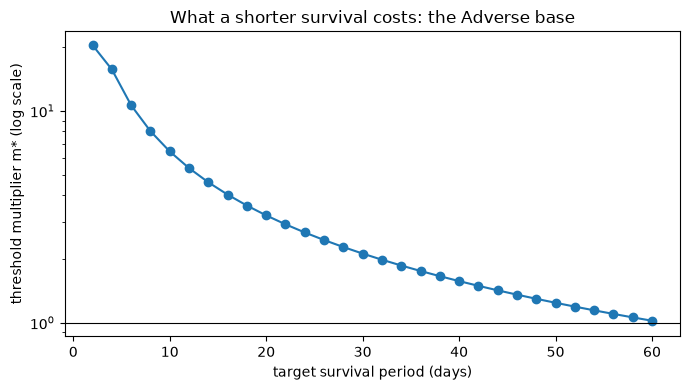

In [8]:
# The threshold multiplier of the Adverse base for every target from 2 to 60 days
targets = list(range(2, 62, 2))
multipliers = [solve_multiplier(scenario, effective_cbc, t).multiplier for t in targets]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(targets, multipliers, marker="o")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.set_xlabel("target survival period (days)")
ax.set_ylabel("threshold multiplier m* (log scale)")
ax.set_title("What a shorter survival costs: the Adverse base")
fig.tight_layout()
plt.show()

The multiplier falls as the target gets longer and approaches 1 as the target approaches the base survival of 62 days, where the engine stops answering: at 62 the base already meets the target. A short target is expensive, 12.65873 times the tables for 5 days against 2.047593 for 31 days, and the curve is steepest at the short end, so the answer of the notebook, 2.118175 for 30 days, sits on the flat part. Every point is a threshold, not an estimate. The figure covers only the targets that the engine accepts; the refusals above are the ones that cannot be drawn.

### Step 5: monotonicity of the survival period

The survival period must not lengthen as the scenario gets more severe (ECB, 2019, and the research dossier). The test `liq.survival_monotone_in_severity` takes a list of survival periods ordered from the mildest to the most severe scenario (with "survives the horizon" counted as longer than any day) and returns the largest lengthening along the order, in days: green if it is zero. The document runs it along the curve of each base. The next cell runs it on the curves of step 2, across the two LiST severities (Adverse then Extreme), and on a planted violation (the reverse order) to show what a red looks like.

In [9]:
# The monotonicity test along each curve, across the two severities, and on a planted violation
from riskvalidation.validation.liquidity import survival_monotone_in_severity

for base_id, (grid, days) in curves.items():
    along = survival_monotone_in_severity(days)
    print(base_id, "| along the curve: largest lengthening (days):", along.statistic, along.light.value)

at_tables = np.array([1.0])
base_survival = [survival_vs_multiplier(*built[b], at_tables)[0].day for b in ("list-adverse", "list-extreme")]
across = survival_monotone_in_severity(base_survival)
planted = survival_monotone_in_severity(base_survival[::-1])
print("across severities (Adverse, Extreme):", base_survival, "|", across.statistic, across.light.value)
print("planted violation (Extreme, Adverse):", base_survival[::-1], "|", planted.statistic, planted.light.value)

list-adverse | along the curve: largest lengthening (days): 0.0 green
list-extreme | along the curve: largest lengthening (days): 0.0 green
across severities (Adverse, Extreme): [62, 41] | 0.0 green
planted violation (Extreme, Adverse): [41, 62] | 21.0 red


### Step 6: the cliff diagnostic

The last test of the package that notebook 01 introduced is the cliff effect between day 30 and day 35 as a share of total assets, $(\mathrm{NLP}(35) - \mathrm{NLP}(30)) / \mathrm{TA}$. `liq.cliff_effect_diagnostic` grades it with two conventions of the product (amber below -0.01, red below -0.03), because the ECB's note defines no limit; it is a diagnostic of the shape of the position, not a regulatory threshold. The next cell calls the test on the committed NLP series of both bases.

In [10]:
# The cliff diagnostic on the committed NLP series of the two LiST bases
from riskvalidation.validation.liquidity import cliff_effect_diagnostic

for base_id in ("list-adverse", "list-extreme"):
    document = documents[base_id]["outputs"]
    nlp = np.array(document["path"]["ladder"]["nlp"])
    diagnostic = cliff_effect_diagnostic(nlp, document["balance_sheet"]["total_assets"])
    print(base_id, "| cliff effect:", round(diagnostic.statistic, 6), "| light:", diagnostic.light.value)
    print("   change of the NLP (USD billions):", round(diagnostic.metric / 1e6, 3))

list-adverse | cliff effect: -0.022246 | light: amber
   change of the NLP (USD billions): -4.65
list-extreme | cliff effect: -0.029776 | light: amber
   change of the NLP (USD billions): -6.224


The last cell draws the NLP of both LiST bases with the cliff window between day 30 and day 35 shaded.

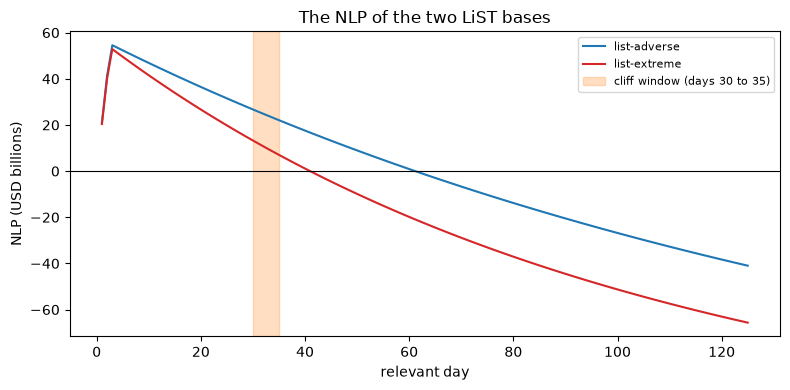

In [11]:
# Draw the NLP of both LiST bases with the cliff window between day 30 and day 35
fig, ax = plt.subplots(figsize=(8, 4))
for base_id, color in (("list-adverse", "tab:blue"), ("list-extreme", "tab:red")):
    series = np.array(documents[base_id]["outputs"]["path"]["ladder"]["nlp"])
    ax.plot(np.arange(1, len(series) + 1), series / 1e6, color=color, label=base_id)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvspan(30, 35, color="tab:orange", alpha=0.25, label="cliff window (days 30 to 35)")
ax.set_xlabel("relevant day")
ax.set_ylabel("NLP (USD billions)")
ax.set_title("The NLP of the two LiST bases")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both positions lose ground through the shaded window: 4.65 billion USD on the Adverse base and 6.224 billion on the Extreme base, a cliff effect of -0.022246 and -0.029776 as a share of total assets. Both are amber under the two conventions of the product, and the Extreme base sits just above the red line of -0.03. The two curves cross zero on days 62 and 41, well after the window, so the cliff is a signal about the shape of the position and not about the day of failure. The figure shows the shape; the grades are conventions of the product, since the ECB note defines no limit.

## Results

**Answer:** For the bank to survive only 30 days, the run-off rates must be 2.118175 times faster than the LiST Adverse table and 1.383141 times faster than the Extreme one. At those multipliers the survival period is 30 days and one hair below them it is 31, so they are thresholds, not estimates, and the distance is short: doubling the Adverse rates already takes the bank from 62 days to 32. The engine refuses the targets it cannot support, 62 and 124 because the base already meets them and 125 and 200 because they are not below the horizon, and returns no number for them.

- **Effective CBC.** With the effective CBC the identity test finds a largest residual of 7e-09 on the Adverse ladder and 3e-08 on the Extreme one, green.
- **Cap and curves.** The cap is 145.234634 for Adverse and 93.876528 for Extreme. Under Adverse the survival period goes from 62 days at $m = 1$ to 32 at 2, 5 at 13 and 1 from 21 on; under Extreme from 41 to 21 at 2, 4 at 13 and 1 from 21 on. Both curves are non-increasing.
- **The threshold multipliers.** The survival period at 2.118175 (Adverse) and 1.383141 (Extreme) is 30, and one hair below them it is 31. The round trip is green with statistic 0.0.
- **Refusals.** For targets of 5 and 31 days the Adverse base gives multipliers of 12.65873 and 2.047593. A target of 62 or 124 days is refused because the base survival period (62 days) is already at or below it; a target of 125 or 200 days is refused because it is not below the horizon. The fast-run base, as baked, is refused for the same last reason (a target of 30 days against a horizon of 5): no number is invented.
- **Monotonicity.** Along each curve the largest lengthening of the survival period is 0.0 days, green; across the two severities ([62, 41]) it is 0.0 and green. The planted reverse order ([41, 62]) lengthens by 21.0 days and is red, which shows that the test can fail.
- **The cliff diagnostic.** The cliff effect is -0.022246 on the Adverse base and -0.029776 on the Extreme base; both are amber under the two conventions of the product. The Extreme base sits just above the red line of -0.03.

What this notebook does not show: whether such a multiplier is plausible against what happened in 2023 (that is the question of notebooks 07 and 08), or how the multiplier would change with a different CBC schedule. The multipliers are properties of the synthetic behaviour of the case.

## Summary

- The reverse stress inverts the question of a scenario: instead of "how long does the bank survive under this run-off?", "how much faster must the run-off be for the bank to last only a target?".
- The answer is a multiplier of the daily rates, capped so that no rate exceeds 1, and it is a threshold: the target is reached at it and not just below it.
- The engine refuses a target with its reason instead of returning a number it cannot support.
- The tests of the package check the identity of the NLP, the round trip of the solver and the monotonicity of the survival period, and each is committed with the engine version that baked it.

**What to try next.** Change the target of step 4 to 45 and 90 days and look at how the multiplier moves; then continue with notebook 07.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3 (the run-off rates of the bases). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10 (stress tests in short-term and protracted, institution-specific and market-wide scenarios). https://www.bis.org/publ/bcbs144.htm